# Calibracao das probabilidades preditas pelos cinco algoritmos

Este notebook avalia a calibracao das probabilidades de obito preditas pelos cinco algoritmos sobre o teste de 2024, alem da capacidade de ordenacao e discriminacao ja avaliada nos notebooks anteriores desta fase.
Um modelo bem calibrado produz probabilidades que correspondem, na media, a frequencia observada de obito entre os casos com aquela probabilidade predita, o que e essencial se as probabilidades forem usadas diretamente para apoiar decisao clinica, e nao apenas para ordenar os casos por risco.
A calibracao e avaliada de duas formas complementares: pelo Brier Skill Score, que resume a qualidade das probabilidades num unico numero relativo a um modelo de referencia, e por curvas de calibracao, que mostram visualmente se as probabilidades preditas estao sistematicamente acima ou abaixo da frequencia observada ao longo da faixa de risco.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessamento.py`, e cria os diretorios de saida usados ao longo do notebook.
A tabela de calibracao por decil e salva em `analysis/results_avaliacao/`, e os graficos de curvas de calibracao sao salvos em `analysis/plots/avaliacao/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessamento

DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_avaliacao"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "avaliacao"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "cart", "random_forest", "xgboost", "lightgbm"]
NUMERO_DECIS = 10

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real salvos pela fase de modelagem para o teste de 2024, e calcula a prevalencia observada de obito nesse conjunto.
Essa prevalencia e usada na secao seguinte como a probabilidade constante do modelo de referencia do Brier Skill Score.

In [2]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet")
    for algoritmo in ALGORITMOS
}

alvo_real_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].to_numpy()
prevalencia_obito_teste2024 = alvo_real_teste2024.mean()

prevalencia_obito_teste2024

np.float64(0.05228758169934641)

Calcula o Brier Score do modelo de referencia, que sempre prediz a prevalencia observada de obito para todos os casos, e o Brier Score de cada um dos cinco algoritmos, usando `avaliar_predicoes` de `utils/preprocessamento.py`.
O Brier Skill Score de cada algoritmo e definido como `1 - brier_modelo / brier_referencia`, de forma que um BSS positivo indica que o algoritmo produz probabilidades mais proximas da frequencia observada do que a referencia ingenua, um BSS igual a zero indica desempenho equivalente ao da referencia, e um BSS negativo indica que o algoritmo e pior que simplesmente prever a prevalencia para todos os casos.

In [3]:
probabilidade_referencia = np.full(len(alvo_real_teste2024), prevalencia_obito_teste2024)
brier_referencia = brier_score_loss(alvo_real_teste2024, probabilidade_referencia)

linhas_bss = []
for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    metricas = preprocessamento.avaliar_predicoes(alvo_real_teste2024, probabilidade_predita)
    brier_skill_score = 1 - metricas["brier_score"] / brier_referencia
    linhas_bss.append(
        {
            "algoritmo": algoritmo,
            "brier_score": metricas["brier_score"],
            "brier_score_referencia": brier_referencia,
            "brier_skill_score": brier_skill_score,
        }
    )

tabela_bss = pd.DataFrame(linhas_bss).sort_values("brier_skill_score", ascending=False).reset_index(drop=True)
tabela_bss.to_csv(DIRETORIO_RESULTADOS_ANALISE / "brier_skill_score_teste2024.csv", index=False)
tabela_bss

,algoritmo,brier_score,brier_score_referencia,brier_skill_score
0,random_forest,0.066271,0.049554,-0.337367
1,lightgbm,0.180938,0.049554,-2.651353
2,xgboost,0.181249,0.049554,-2.657637
3,cart,0.207120,0.049554,-3.179715
4,regressao_logistica,0.231823,0.049554,-3.678233


Constroi, para cada algoritmo, a tabela de calibracao por decil de probabilidade predita.
Os casos do teste de 2024 sao divididos em decis pela propria probabilidade predita de cada algoritmo, usando `pd.qcut`, e para cada decil sao calculados o numero de casos, a probabilidade media predita e a fracao observada de obito.
Quando um algoritmo produz poucos valores distintos de probabilidade, como o CART, decis adjacentes podem ter a mesma fronteira e serem automaticamente combinados por `pd.qcut`, o que resulta em menos de dez decis efetivos para esse algoritmo.

In [4]:
tabelas_calibracao_por_decil = []
for algoritmo in ALGORITMOS:
    tabela_algoritmo = predicoes_teste2024[algoritmo].copy()
    tabela_algoritmo["decil"] = pd.qcut(
        tabela_algoritmo["probabilidade_predita"], NUMERO_DECIS, labels=False, duplicates="drop"
    )

    resumo_decis = (
        tabela_algoritmo.groupby("decil")
        .agg(
            numero_casos=("obito", "size"),
            probabilidade_media_predita=("probabilidade_predita", "mean"),
            fracao_observada_obito=("obito", "mean"),
        )
        .reset_index()
    )
    resumo_decis["decil"] = resumo_decis["decil"] + 1
    resumo_decis["algoritmo"] = algoritmo
    resumo_decis["numero_decis_efetivo"] = resumo_decis["decil"].max()

    tabelas_calibracao_por_decil.append(resumo_decis)

tabela_calibracao_por_decil = pd.concat(tabelas_calibracao_por_decil, ignore_index=True)[
    ["algoritmo", "decil", "numero_decis_efetivo", "numero_casos", "probabilidade_media_predita", "fracao_observada_obito"]
]

tabela_calibracao_por_decil.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "calibracao_por_decil.csv", index=False
)
tabela_calibracao_por_decil

,algoritmo,decil,numero_decis_efetivo,numero_casos,probabilidade_media_predita,fracao_observada_obito
0,regressao_logistica,1,10,398,0.160486,0.005025
1,regressao_logistica,2,10,398,0.239113,0.007538
2,regressao_logistica,3,10,398,0.293779,0.015075
3,regressao_logistica,4,10,397,0.348254,0.007557
4,regressao_logistica,5,10,398,0.407326,0.017588
5,regressao_logistica,6,10,398,0.470000,0.027638
6,regressao_logistica,7,10,397,0.535624,0.042821
7,regressao_logistica,8,10,398,0.612756,0.057789
8,regressao_logistica,9,10,398,0.701591,0.120603
9,regressao_logistica,10,10,398,0.824382,0.221106


Gera as curvas de calibracao dos cinco algoritmos num unico grafico, usando `calibration_curve` com decis de probabilidade predita.
A diagonal pontilhada representa a calibracao perfeita, em que a probabilidade predita e igual a fracao observada de obito, e curvas acima dessa diagonal indicam subestimacao do risco, enquanto curvas abaixo indicam sobreestimacao.
O grafico e salvo em `analysis/plots/avaliacao/curvas_calibracao_5_algoritmos.png`.

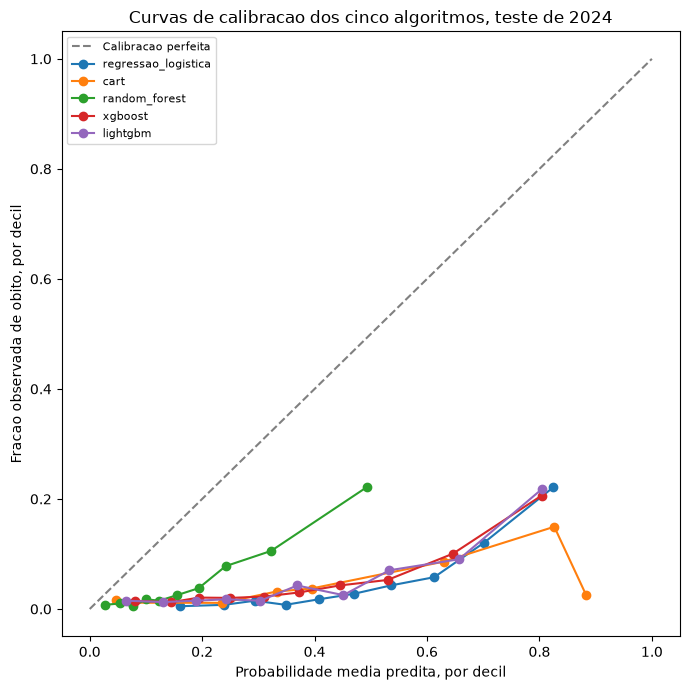

In [5]:
figura, eixo = plt.subplots(figsize=(7, 7))
eixo.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibracao perfeita")

for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    fracao_observada, probabilidade_media = calibration_curve(
        alvo_real_teste2024, probabilidade_predita, n_bins=NUMERO_DECIS, strategy="quantile"
    )
    eixo.plot(probabilidade_media, fracao_observada, marker="o", label=algoritmo)

eixo.set_xlabel("Probabilidade media predita, por decil")
eixo.set_ylabel("Fracao observada de obito, por decil")
eixo.set_title("Curvas de calibracao dos cinco algoritmos, teste de 2024")
eixo.legend(loc="upper left", fontsize=8)
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "curvas_calibracao_5_algoritmos.png", dpi=150)
plt.show()

Gera o mesmo conjunto de curvas de calibracao em paineis separados por algoritmo, com a mesma escala de eixos para os cinco paineis, o que facilita a leitura individual de cada curva sem a sobreposicao visual do grafico unico anterior.
O grafico e salvo em `analysis/plots/avaliacao/curvas_calibracao_por_algoritmo.png`.

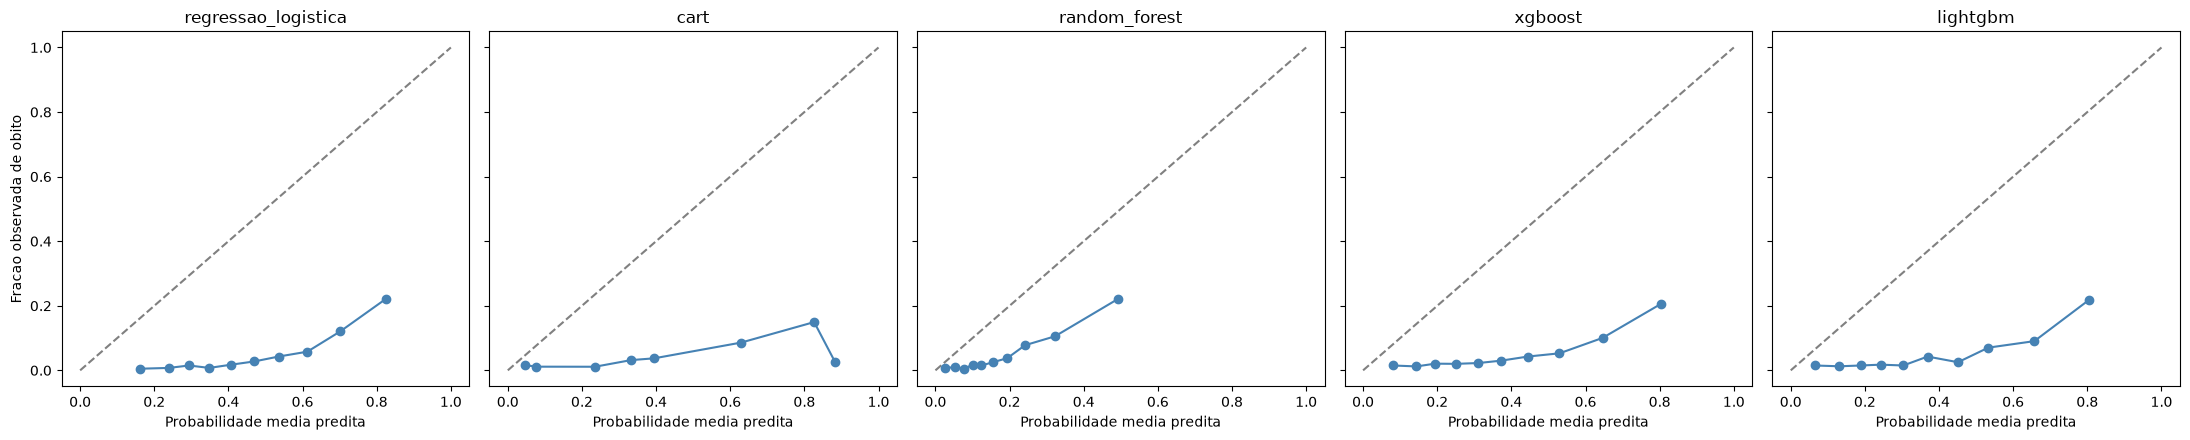

In [6]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(22, 4.5), sharex=True, sharey=True)

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    fracao_observada, probabilidade_media = calibration_curve(
        alvo_real_teste2024, probabilidade_predita, n_bins=NUMERO_DECIS, strategy="quantile"
    )
    eixo_atual.plot([0, 1], [0, 1], linestyle="--", color="gray")
    eixo_atual.plot(probabilidade_media, fracao_observada, marker="o", color="steelblue")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Probabilidade media predita")

eixos[0].set_ylabel("Fracao observada de obito")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "curvas_calibracao_por_algoritmo.png", dpi=150)
plt.show()

## Sintese dos achados

O Brier Skill Score dos cinco algoritmos e negativo em todos os casos, de -0,337 para o Random Forest a -3,678 para a Regressao Logistica, o que significa que nenhum dos cinco algoritmos supera, em Brier Score absoluto, o modelo de referencia trivial que sempre prediz a prevalencia observada de obito, 5,23 por cento, para todos os casos.
Essa e uma consequencia direta da baixa prevalencia de obito combinada com o objetivo de discriminar os casos de maior risco, e nao uma falha isolada de um algoritmo especifico.
A referencia trivial ja acerta a maioria das observacoes ao prever um numero pequeno para quase todos os casos, que de fato nao evoluem a obito, enquanto qualquer modelo que atribua probabilidades altas aos casos de maior risco paga um custo em erro quadratico sempre que esse risco elevado nao se concretiza, o que e frequente mesmo nos decis de maior risco, ja que a prevalencia de obito permanece baixa mesmo entre os casos mais graves.
O Random Forest tem o Brier Skill Score menos negativo entre os cinco algoritmos, o que confirma, em termos relativos ao modelo de referencia, a leitura ja indicada pelo Brier Score absoluto na fase de modelagem.
A tabela por decil mostra a razao concreta dessa vantagem relativa: no decil de maior risco, a probabilidade media predita pelo Random Forest e 0,492 contra uma fracao observada de obito de 0,221, uma distancia bem menor do que a da Regressao Logistica, cujo decil de maior risco tem probabilidade media de 0,824 contra a mesma fracao observada de obito de 0,221.
Esse deslocamento acentuado da Regressao Logistica para probabilidades muito acima da frequencia real, visivel em quase todos os decis na curva de calibracao, e consequencia direta do uso de `class_weight="balanced"`, que melhora a discriminacao entre as classes mas piora sistematicamente a correspondencia entre a probabilidade predita e a frequencia real.
XGBoost e LightGBM tem Brier Skill Score muito proximos entre si, -2,658 e -2,651, e padroes de calibracao semelhantes, tambem com probabilidades deslocadas para cima em relacao a diagonal de calibracao perfeita ao longo de quase toda a faixa de risco, embora de forma menos extrema do que a Regressao Logistica.
O CART tem poucos valores distintos de probabilidade predita, o que reduz a oito o numero de decis efetivos nessa analise, e seu ultimo decil mostra uma fracao observada de obito de apenas 0,026 apesar de uma probabilidade media predita de 0,883, a maior distancia entre probabilidade predita e frequencia observada entre todos os algoritmos e decis analisados.
Em conjunto, estes resultados indicam que a boa capacidade de ordenacao de risco dos cinco algoritmos, ja documentada pela AUPRC e pelo ROC-AUC na fase de modelagem, nao se traduz em probabilidades absolutas bem calibradas em relacao a uma referencia ingenua, e que o Random Forest, apesar disso, e o algoritmo cujas probabilidades mais se aproximam da frequencia observada de obito entre os cinco avaliados.

## Recalibracao isotonica das probabilidades

O diagnostico anterior mostra que os cinco algoritmos tem Brier Skill Score negativo no teste de 2024, uma consequencia direta do uso de class_weight="balanced" ou scale_pos_weight no treino, que melhora a capacidade de ordenar os casos por risco mas desloca as probabilidades preditas para valores sistematicamente acima da frequencia observada de obito.
Esta secao corrige esse problema por recalibracao isotonica, uma transformacao que ajusta o nivel absoluto das probabilidades preditas para que corresponda a frequencia observada de obito.

A recalibracao usa sklearn.calibration.CalibratedClassifierCV, ajustado exclusivamente sobre o treino de 2020 a 2023 com os mesmos tres folds de validacao temporal por expanding window usados na busca de hiperparametros da fase de modelagem, de forma que nenhuma informacao do teste de 2024 ou da validacao externa de 2025 entra no ajuste do recalibrador.
Como esses tres folds nao cobrem o ano de 2020 como validacao, o CalibratedClassifierCV precisa treinar um modelo separado por fold em vez de aplicar uma unica transformacao isotonica ao modelo final treinado em todo o periodo, o que muda moderadamente, e nao apenas por empates, o valor absoluto da AUPRC e do ROC-AUC de cada algoritmo em relacao as probabilidades nao calibradas, ainda que a ordem relativa entre os cinco algoritmos tenda a se manter proxima da original.

A partir desta secao, os artefatos com o sufixo _calibrado, tanto as predicoes de probabilidade quanto o modelo salvo, passam a ser a estimativa recomendada de risco real de obito para qualquer uso futuro do estudo que dependa do valor absoluto da probabilidade predita, como eventual apoio a decisao clinica.
Os artefatos sem esse sufixo continuam validos para qualquer analise baseada na ordenacao dos casos, como a importancia de variaveis ou a comparacao de AUPRC entre subgrupos, por serem os mesmos artefatos ja usados nas demais fases deste estudo.

Importa clone e CalibratedClassifierCV do scikit-learn, carrega os conjuntos de preditores de treino, teste de 2024 e validacao de 2025 ja construidos pelo pipeline de dados, e reconstroi os mesmos tres folds de validacao temporal por expanding window usados na fase de modelagem.
Esses folds garantem que o recalibrador seja ajustado com o mesmo protocolo de validacao temporal usado no restante do estudo.

In [7]:
import joblib
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_MODELOS = PROJECT_ROOT / "output" / "modelos"

X_train = pd.read_parquet(DIRETORIO_FEATURES / "X_train.parquet")
y_train = pd.read_parquet(DIRETORIO_FEATURES / "y_train.parquet")[preprocessamento.COLUNA_ALVO]
X_test = pd.read_parquet(DIRETORIO_FEATURES / "X_test.parquet")
y_test = pd.read_parquet(DIRETORIO_FEATURES / "y_test.parquet")[preprocessamento.COLUNA_ALVO]
X_val2025 = pd.read_parquet(DIRETORIO_FEATURES / "X_val2025.parquet")
y_val2025 = pd.read_parquet(DIRETORIO_FEATURES / "y_val2025.parquet")[preprocessamento.COLUNA_ALVO]

folds_expanding_window = preprocessamento.construir_folds_expanding_window(
    PROJECT_ROOT, tamanho_treino=len(X_train)
)

X_train.shape, X_test.shape, X_val2025.shape

((7171, 29), (3978, 29), (3241, 29))

Para cada um dos cinco algoritmos, carrega o pipeline ja ajustado na fase de modelagem, clona apenas a estrutura e os hiperparametros, sem reaproveitar nenhum peso ja ajustado, e usa esse clone como estimador base de um CalibratedClassifierCV com metodo isotonico.
Como os tres folds de expanding window nao formam uma particao completa do treino, ja que o ano de 2020 nunca entra como conjunto de validacao, o CalibratedClassifierCV e ajustado no modo padrao de ensemble: para cada um dos tres folds, um clone do estimador base e treinado no respectivo subconjunto de treino e calibrado no respectivo subconjunto de validacao, e a probabilidade final e a media das probabilidades dos tres pares treinado e calibrado.
Essa e a mesma logica de validacao temporal por expanding window ja usada na busca de hiperparametros da fase de modelagem, agora aplicada ao ajuste do recalibrador, de forma que nenhuma informacao do teste de 2024 ou da validacao externa de 2025 entra nesse ajuste.

As probabilidades recalibradas sao geradas para o teste de 2024 e para a validacao externa de 2025, e os artefatos resultantes, as predicoes dos dois anos e o modelo recalibrado, sao salvos em output/metricas/ e output/modelos/ com o sufixo _calibrado, reutilizando salvar_predicoes e salvar_modelo de utils/preprocessamento.py.

In [8]:
modelos_calibrados = {}
predicoes_teste2024_calibrado = {}
predicoes_val2025_calibrado = {}

for algoritmo in ALGORITMOS:
    modelo_ajustado = joblib.load(DIRETORIO_MODELOS / f"{algoritmo}.joblib")
    estimador_base_clonado = clone(modelo_ajustado)

    modelo_calibrado = CalibratedClassifierCV(
        estimator=estimador_base_clonado, method="isotonic", cv=folds_expanding_window
    )
    modelo_calibrado.fit(X_train, y_train)

    probabilidade_teste2024_calibrada = modelo_calibrado.predict_proba(X_test)[:, 1]
    probabilidade_val2025_calibrada = modelo_calibrado.predict_proba(X_val2025)[:, 1]

    preprocessamento.salvar_predicoes(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024_calibrado.parquet",
        probabilidade_teste2024_calibrada,
        y_test,
    )
    preprocessamento.salvar_predicoes(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_val2025_calibrado.parquet",
        probabilidade_val2025_calibrada,
        y_val2025,
    )
    preprocessamento.salvar_modelo(DIRETORIO_MODELOS / f"{algoritmo}_calibrado.joblib", modelo_calibrado)

    modelos_calibrados[algoritmo] = modelo_calibrado
    predicoes_teste2024_calibrado[algoritmo] = pd.read_parquet(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024_calibrado.parquet"
    )
    predicoes_val2025_calibrado[algoritmo] = pd.read_parquet(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_val2025_calibrado.parquet"
    )

list(modelos_calibrados.keys())

['regressao_logistica', 'cart', 'random_forest', 'xgboost', 'lightgbm']

Recalcula AUPRC, ROC-AUC e Brier Score de cada algoritmo no teste de 2024 a partir das probabilidades recalibradas, usando a mesma funcao avaliar_predicoes, e recalcula o Brier Skill Score com a mesma referencia trivial de prevalencia ja usada no diagnostico.
A tabela resultante coloca lado a lado os valores antes e depois da recalibracao para as quatro metricas, e substitui a tabela brier_skill_score_teste2024.csv gerada no diagnostico, que continha apenas os valores antes da recalibracao.

In [9]:
linhas_comparacao_calibracao = []
for algoritmo in ALGORITMOS:
    metricas_nao_calibrado = preprocessamento.avaliar_predicoes(
        alvo_real_teste2024, predicoes_teste2024[algoritmo]["probabilidade_predita"]
    )
    metricas_calibrado = preprocessamento.avaliar_predicoes(
        alvo_real_teste2024, predicoes_teste2024_calibrado[algoritmo]["probabilidade_predita"]
    )

    linhas_comparacao_calibracao.append(
        {
            "algoritmo": algoritmo,
            "auprc_nao_calibrado": metricas_nao_calibrado["auprc"],
            "auprc_calibrado": metricas_calibrado["auprc"],
            "roc_auc_nao_calibrado": metricas_nao_calibrado["roc_auc"],
            "roc_auc_calibrado": metricas_calibrado["roc_auc"],
            "brier_score_nao_calibrado": metricas_nao_calibrado["brier_score"],
            "brier_score_calibrado": metricas_calibrado["brier_score"],
            "brier_score_referencia": brier_referencia,
            "brier_skill_score_nao_calibrado": 1 - metricas_nao_calibrado["brier_score"] / brier_referencia,
            "brier_skill_score_calibrado": 1 - metricas_calibrado["brier_score"] / brier_referencia,
        }
    )

tabela_calibracao_antes_depois_teste2024 = (
    pd.DataFrame(linhas_comparacao_calibracao)
    .sort_values("brier_skill_score_calibrado", ascending=False)
    .reset_index(drop=True)
)
tabela_calibracao_antes_depois_teste2024.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "brier_skill_score_teste2024.csv", index=False
)
tabela_calibracao_antes_depois_teste2024

,algoritmo,auprc_nao_calibrado,auprc_calibrado,roc_auc_nao_calibrado,roc_auc_calibrado,brier_score_nao_calibrado,brier_score_calibrado,brier_score_referencia,brier_skill_score_nao_calibrado,brier_skill_score_calibrado
0,regressao_logistica,0.224153,0.168356,0.820210,0.770657,0.231823,0.047325,0.049554,-3.678233,0.044981
1,random_forest,0.226905,0.154976,0.812126,0.763413,0.066271,0.047747,0.049554,-0.337367,0.036461
2,lightgbm,0.195912,0.119879,0.776203,0.715701,0.180938,0.048713,0.049554,-2.651353,0.016968
3,cart,0.126649,0.091658,0.742949,0.665360,0.207120,0.049538,0.049554,-3.179715,0.000313
4,xgboost,0.196472,0.075509,0.763683,0.611592,0.181249,0.049813,0.049554,-2.657637,-0.005236


Repete a mesma comparacao antes e depois da recalibracao para a validacao externa de 2025, carregando tambem as predicoes nao calibradas desse ano, que nao haviam sido usadas neste notebook ate aqui.
Esta tabela e complementar a anterior, pois confirma se a melhora de calibracao obtida no teste de 2024 se mantem num ano que nao participa nem do treino do modelo nem do ajuste do recalibrador, e e salva separadamente em calibracao_antes_depois_val2025.csv.

In [10]:
predicoes_val2025_nao_calibrado = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_val2025.parquet")
    for algoritmo in ALGORITMOS
}

alvo_real_val2025 = predicoes_val2025_nao_calibrado[ALGORITMOS[0]]["obito"].to_numpy()
prevalencia_obito_val2025 = alvo_real_val2025.mean()
probabilidade_referencia_val2025 = np.full(len(alvo_real_val2025), prevalencia_obito_val2025)
brier_referencia_val2025 = brier_score_loss(alvo_real_val2025, probabilidade_referencia_val2025)

linhas_comparacao_calibracao_val2025 = []
for algoritmo in ALGORITMOS:
    metricas_nao_calibrado = preprocessamento.avaliar_predicoes(
        alvo_real_val2025, predicoes_val2025_nao_calibrado[algoritmo]["probabilidade_predita"]
    )
    metricas_calibrado = preprocessamento.avaliar_predicoes(
        alvo_real_val2025, predicoes_val2025_calibrado[algoritmo]["probabilidade_predita"]
    )

    linhas_comparacao_calibracao_val2025.append(
        {
            "algoritmo": algoritmo,
            "auprc_nao_calibrado": metricas_nao_calibrado["auprc"],
            "auprc_calibrado": metricas_calibrado["auprc"],
            "roc_auc_nao_calibrado": metricas_nao_calibrado["roc_auc"],
            "roc_auc_calibrado": metricas_calibrado["roc_auc"],
            "brier_score_nao_calibrado": metricas_nao_calibrado["brier_score"],
            "brier_score_calibrado": metricas_calibrado["brier_score"],
            "brier_score_referencia": brier_referencia_val2025,
            "brier_skill_score_nao_calibrado": 1 - metricas_nao_calibrado["brier_score"] / brier_referencia_val2025,
            "brier_skill_score_calibrado": 1 - metricas_calibrado["brier_score"] / brier_referencia_val2025,
        }
    )

tabela_calibracao_antes_depois_val2025 = (
    pd.DataFrame(linhas_comparacao_calibracao_val2025)
    .sort_values("brier_skill_score_calibrado", ascending=False)
    .reset_index(drop=True)
)
tabela_calibracao_antes_depois_val2025.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "calibracao_antes_depois_val2025.csv", index=False
)
tabela_calibracao_antes_depois_val2025

,algoritmo,auprc_nao_calibrado,auprc_calibrado,roc_auc_nao_calibrado,roc_auc_calibrado,brier_score_nao_calibrado,brier_score_calibrado,brier_score_referencia,brier_skill_score_nao_calibrado,brier_skill_score_calibrado
0,regressao_logistica,0.117988,0.098326,0.799353,0.783241,0.212253,0.025776,0.026707,-6.947579,0.034828
1,cart,0.079085,0.077709,0.723692,0.735246,0.212404,0.025897,0.026707,-6.953261,0.030308
2,random_forest,0.120737,0.084575,0.804390,0.766556,0.054261,0.026078,0.026707,-1.031750,0.023519
3,lightgbm,0.078388,0.071204,0.709302,0.710337,0.145884,0.026217,0.026707,-4.462468,0.018316
4,xgboost,0.044179,0.040915,0.561532,0.608811,0.135673,0.026721,0.026707,-4.080127,-0.000530


Gera, num painel com um grafico por algoritmo, as curvas de calibracao antes e depois da recalibracao isotonica no teste de 2024, na mesma escala de eixos para os cinco paineis.
A curva antes da recalibracao e a mesma ja mostrada na secao de diagnostico, e a curva depois usa as probabilidades recalibradas desta secao, o que permite comparar visualmente, para cada algoritmo, o quanto a recalibracao aproximou a curva da diagonal de calibracao perfeita.

O grafico e salvo em analysis/plots/avaliacao/curvas_calibracao_antes_depois_recalibracao.png.

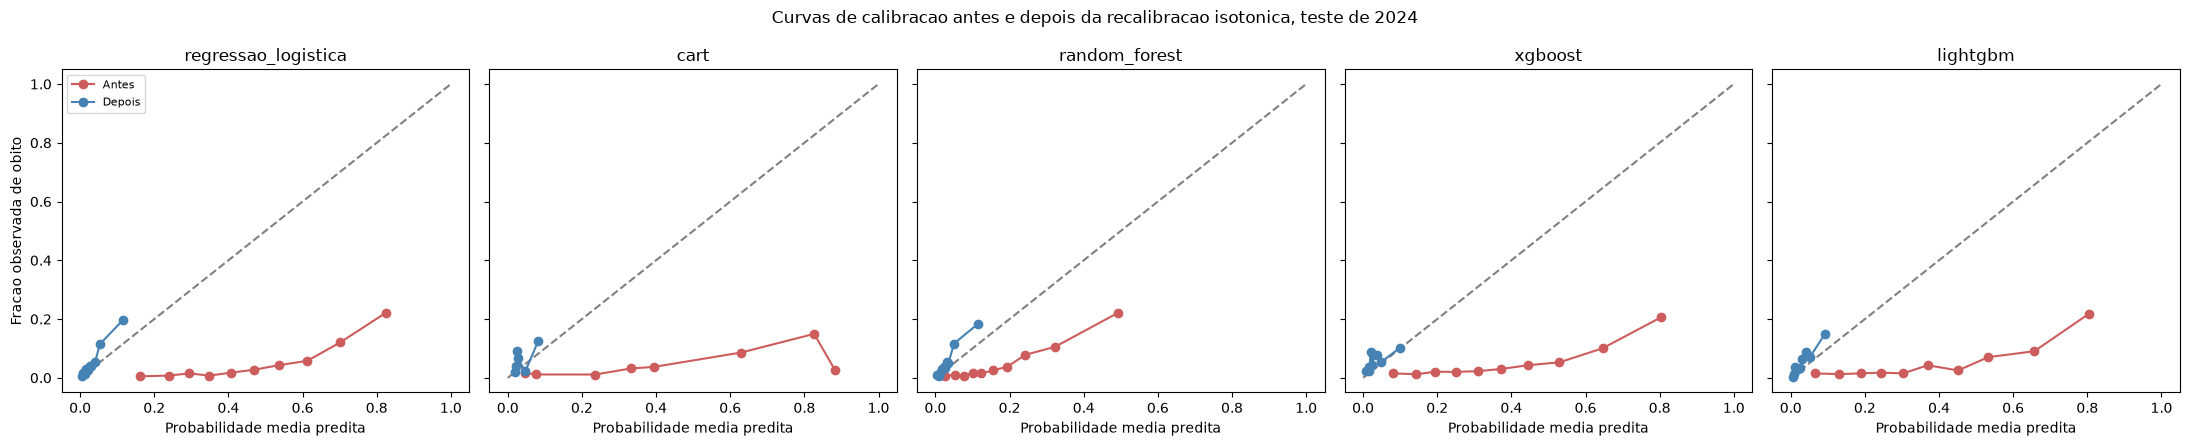

In [11]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(22, 4.5), sharex=True, sharey=True)

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    probabilidade_antes = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    probabilidade_depois = predicoes_teste2024_calibrado[algoritmo]["probabilidade_predita"].to_numpy()

    fracao_observada_antes, probabilidade_media_antes = calibration_curve(
        alvo_real_teste2024, probabilidade_antes, n_bins=NUMERO_DECIS, strategy="quantile"
    )
    fracao_observada_depois, probabilidade_media_depois = calibration_curve(
        alvo_real_teste2024, probabilidade_depois, n_bins=NUMERO_DECIS, strategy="quantile"
    )

    eixo_atual.plot([0, 1], [0, 1], linestyle="--", color="gray")
    eixo_atual.plot(probabilidade_media_antes, fracao_observada_antes, marker="o", color="indianred", label="Antes")
    eixo_atual.plot(probabilidade_media_depois, fracao_observada_depois, marker="o", color="steelblue", label="Depois")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Probabilidade media predita")

eixos[0].set_ylabel("Fracao observada de obito")
eixos[0].legend(loc="upper left", fontsize=8)
figura.suptitle("Curvas de calibracao antes e depois da recalibracao isotonica, teste de 2024")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "curvas_calibracao_antes_depois_recalibracao.png", dpi=150)
plt.show()

## Conclusao da recalibracao

A recalibracao isotonica resolve o problema de calibracao absoluta dos cinco algoritmos no teste de 2024: o Brier Skill Score deixa de ser fortemente negativo em todos os casos e passa a ficar proximo de zero, positivo para quatro dos cinco algoritmos e apenas marginalmente negativo para o XGBoost, -0,005.
Esse ganho de calibracao vem acompanhado de uma reducao moderada na AUPRC e no ROC-AUC de todos os algoritmos, uma consequencia do proprio esquema de validacao cruzada por expanding window usado para evitar vazamento, que exige treinar o CalibratedClassifierCV como um ensemble de tres modelos ajustados cada um numa fracao do periodo de treino, em vez de recalibrar diretamente o modelo final treinado em todo o periodo.

A Regressao Logistica tem o Brier Skill Score mais alto apos a recalibracao, 0,045 no teste de 2024, confirmando que o deslocamento sistematico de probabilidade identificado no diagnostico, causado por class_weight="balanced", era corrigivel por uma transformacao isotonica, e sua AUPRC recalibrada, 0,168, continua entre as duas melhores do grupo.
O Random Forest, antes o algoritmo com a calibracao menos ruim entre os cinco, tambem termina entre os melhores depois da recalibracao, com Brier Skill Score de 0,036, e a queda relativa de sua AUPRC, de 0,227 para 0,155, fica proxima da media dos cinco algoritmos.
O LightGBM e o CART terminam com Brier Skill Score positivo mas pequeno, 0,017 e 0,0003 respectivamente, o que indica uma calibracao apenas marginalmente melhor que a referencia trivial de prevalencia mesmo depois da correcao, e ambos mantem AUPRC moderada depois da recalibracao, 0,120 e 0,092.
O XGBoost e o unico algoritmo cujo Brier Skill Score permanece levemente negativo apos a recalibracao, -0,005, e tambem o que mais perde em discriminacao, com a AUPRC caindo de 0,196 para 0,076 e o ROC-AUC de 0,764 para 0,612, repetindo o padrao de instabilidade ja observado para esse algoritmo na comparacao entre o teste de 2024 e a validacao externa de 2025.

A mesma comparacao na validacao externa de 2025 confirma que a melhora de calibracao nao e um artefato do teste de 2024: o Brier Skill Score dos cinco algoritmos tambem sai de valores fortemente negativos, entre -1,03 e -6,95, para valores proximos de zero, entre -0,0005 e 0,035, com a mesma excecao do XGBoost permanecendo marginalmente negativo.
Em conjunto, a recalibracao isotonica cumpre o objetivo desta fase: torna as probabilidades preditas interpretaveis como estimativa de risco real para os cinco algoritmos, ao custo de uma discriminacao absoluta menor do que a dos modelos originais, o que reforca a recomendacao de usar os artefatos `_calibrado` sempre que o valor absoluto da probabilidade for relevante, e os artefatos originais sempre que apenas a ordenacao dos casos importar.